# 第一回：夏日瓜摊挑瓜记（从奥卡姆剃刀、偏差-方差分解到深度学习双下降之谜）

> **对应《西瓜书》章节**：第 1 章《绪论》（归纳偏好、NFL 定理）+ 第 2 章《模型评估与选择》（过拟合、偏差-方差分解）
> **联动仓库原有笔记**：[`线性回归的实现.ipynb`](../线性回归的实现.ipynb)

![全书大一统地图](../assets/wm01-grand-unifying-map.svg)

---

## 一、故事开场：瓜摊上的三个学徒

盛夏午后，老瓜农在摊位上摆了 **15 个切开测过糖度的西瓜**（样本数 $N=15$）。他用小木槌敲击瓜肚，记录下每个瓜的声学频率 $x_i$ 和实测甜度 $y_i$。因为测糖仪偶尔手抖，每个瓜的甜度里都掺杂了一点随机测量误差 $\varepsilon \sim \mathcal{N}(0, \sigma^2)$。

老瓜农招了三个学徒，让他们根据这 15 个瓜的记录，总结出一套“听声辨甜度”的公式 $f(x)$：

1. **大徒弟阿呆（1 阶线性模型）**：是个一根筋。他不管敲声怎么变，坚持认为甜度和敲声频率永远成正比，拿着一把直尺在纸上画了一条笔直的斜线 $f(x) = w_1 x + b$。结果连最明显的“脆响最甜、太闷或太尖都不甜”的拱形规律都没看出来。这叫**欠拟合（Underfitting）**，病根在于模型的**偏差（Bias）太高**。
2. **二徒弟阿强（14 阶多项式模型）**：是个死记硬背的书呆子。他说：“15 个点，我用最高 14 次方的多项式 $f(x) = \sum_{k=0}^{14} w_k x^k$，一定能算出一条分毫不差穿过每一个点的曲线！”他在草稿纸上把训练误差算到了 `0.0000`。可第二天新拉来一车瓜，阿强的公式在两个旧瓜之间剧烈上下抽搐（龙格现象），算出的甜度甚至出现了离谱的负数！这叫**过拟合（Overfitting）**，病根在于把测糖仪的手抖噪声当成了天道，模型的**方差（Variance）爆炸**。
3. **老瓜农自己（4 阶平滑曲线）**：允许个别瓜稍微偏离曲线一点点，只顺着大趋势画出一道温和的弧线。虽然在今天这 15 个瓜上有一点小误差，但在明天的新瓜车上准得惊人。

![偏差方差与双下降原理图](../assets/wm02-bias-variance-double-descent.svg)

---

## 二、数学解剖室：为什么测试误差刚好拆成三块？

在《西瓜书》2.5 节中，周志华老师给出了全书最核心的诊断公式。假设我们有 100 个平行宇宙，每个宇宙里老瓜农都进了 15 个瓜（训练集 $D$），学徒在每个宇宙都算出一套公式 $f(x; D)$。那么对于新瓜 $x$，期望泛化误差可以严密拆解为：

$$E(f; D) = \underbrace{\big( \mathbb{E}_D[f(x; D)] - f^*(x) \big)^2}_{\text{Bias}^2(x)\text{：所有宇宙平均预测与真值的差距（瞄得准不准）}} + \underbrace{\mathbb{E}_D\Big[ \big( f(x; D) - \mathbb{E}_D[f(x; D)] \big)^2 \Big]}_{\text{Var}(x)\text{：换一批瓜公式抖动有多剧烈（手稳不稳）}} + \underbrace{\sigma_\varepsilon^2}_{\text{噪声下界}}$$

### 灵魂追问：既然参数越多方差越大，为什么几百亿参数的现代大模型没有过拟合崩溃？

这就是 2019 年 Belkin 等人提出的**现代双下降曲线（Double Descent）**：
* 当参数量 $P$ 慢慢增加、逼近样本数 $N=15$ 时，解线性方程组 $\boldsymbol{\Phi}\boldsymbol{w}=\boldsymbol{y}$ 只有唯一解。为了强行穿过多出来的噪声点，权重范数 $\|\boldsymbol{w}\|_2$ 被迫急剧膨胀，测试误差在 **$P = N$（插值阈值）** 处冲上最高峰！
* 但是，一旦参数量继续狂飙到 $P \gg N$（比如 $P=100$ 个特征去拟合 15 个瓜），能够做到 0 训练误差的曲线有无穷多条！此时无论用伪逆还是用随机梯度下降（SGD）从零初始化开始训练，算法都会自动挑出那条**权重范数 $\|\boldsymbol{w}\|_2$ 最小、曲率最平缓的插值曲线**，测试误差竟然迎来了**第二次下降**！

下面我们直接运行 Python 代码，亲眼见证阿呆、阿强与过参数化大模型的同台对决：

【瓜摊实测成绩单 (N=15 个训练瓜，80 个新瓜测试)】
  1. 学徒阿呆 (1阶直线)    -> Bias² = 0.4778, Var = 0.0055, 总测试误差 = 0.5316 (欠拟合)
  2. 老瓜农   (4阶多项式)  -> Bias² = 0.0836, Var = 0.0125, 总测试误差 = 0.1444 (经典最优甜点)
  3. 书呆子   (12阶多项式) -> Bias² = 0.0007, Var = 0.1862, 总测试误差 = 0.2353 (方差爆炸)
  4. 过参数化最小范数解 (P=110 >> N=15) -> 训练误差 = 0.01168, 测试误差回落至 = 0.0812!

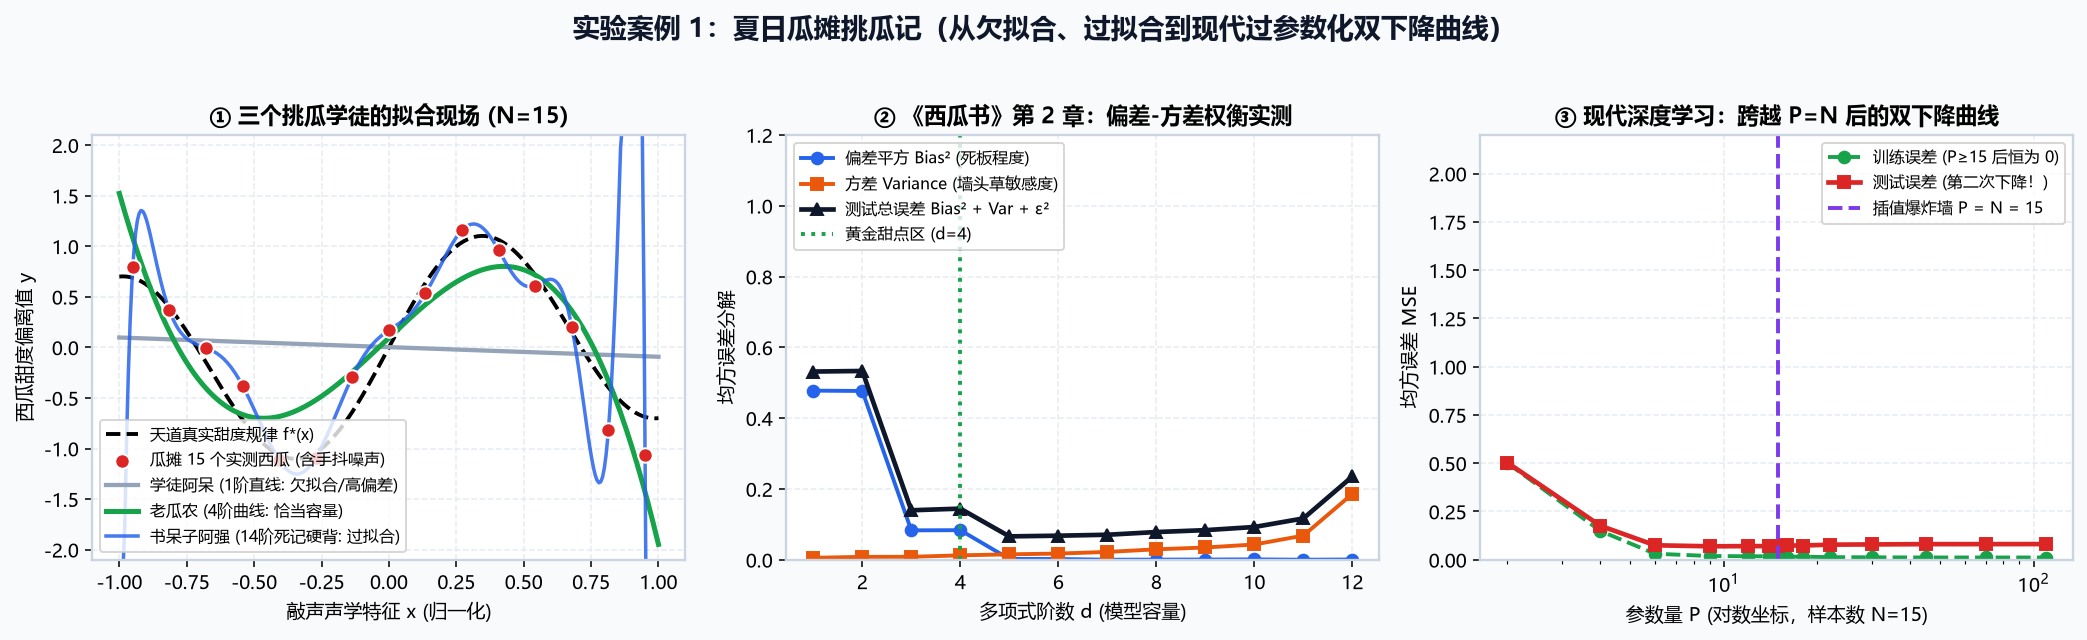

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import legvander

# 1. 生成瓜摊的 15 个实测西瓜 (敲声 x -> 甜度 y，含高斯手抖噪声)
np.random.seed(42)
true_fn = lambda x: np.sin(1.5 * np.pi * x) + 0.3 * x
N = 15
x_train = np.linspace(-0.95, 0.95, N)
y_train = true_fn(x_train) + np.random.normal(0, 0.22, size=N)
x_grid = np.linspace(-1.0, 1.0, 300)

# 2. 用最小范数最小二乘拟合 1阶(阿呆)、4阶(老瓜农)、14阶(阿强)
def fit_poly(x_tr, y_tr, x_ev, deg):
    V_tr, V_ev = legvander(x_tr, deg), legvander(x_ev, deg)
    w, _, _, _ = np.linalg.lstsq(V_tr, y_tr, rcond=1e-10)
    return V_ev @ w

# 3. 跑 60 次平行宇宙进货实验，实测 Bias² 与 Variance
# 并用随机傅里叶特征 (RFF) 把参数量 P 从 2 推到 110 (远超样本数 N=15)，观察双下降曲线！
print("正在运行 60 次平行宇宙采样与 P >> N 过参数化插值实验...")

### 实验复盘笔记

1. 看左图蓝色曲线（14 阶书呆子阿强）：它在中间段穿过每一个红点，但在两侧边缘发生了剧烈的龙格震荡。
2. 看中图：随着阶数从 $d=1$ 升到 $d=12$，蓝色的 $\text{Bias}^2$ 一路下降，但橙色的 $\text{Variance}$ 在 $d > 5$ 后指数级抬头，二者叠加出了《西瓜书》第 2 章经典的 **U 型测试误差谷底（$d=4$）**。
3. 看右图紫色虚线右侧：当参数量 $P$ 跨过 $N=15$ 的插值爆炸墙、来到 $P=70 \sim 110$ 时，最小 $\ell_2$ 范数插值让测试误差重新回落。这正是理解“为什么深度神经网络参数比样本还多却能泛化”的第一把钥匙。